<a href="https://colab.research.google.com/github/LeonimerMelo/CNNs/blob/Pretrained_CNNs/Transfer_Learning_%5BVGG16_feature_extractor%5D_v8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Transfer Learning (Aprendizado por Transferência)

O Transfer Learning é uma das técnicas mais importantes do Deep Learning. Ao desenvolver um sistema de visão computacional, normalmente é necessário coletar e rotular uma grande quantidade de imagens para treinar uma rede neural.

Embora seja possível construir uma rede convolucional (CNN) e treiná-la do zero, existe uma alternativa mais eficiente: utilizar uma rede neural que já foi treinada em uma grande base de dados e adaptar seus conhecimentos para resolver um novo problema.

Essa técnica permite aproveitar os pesos e as características aprendidas por um modelo pré-treinado como ponto de partida para treinar uma nova tarefa com uma quantidade menor de dados. Como resultado, o treinamento pode ser mais rápido e apresentar melhor desempenho.

### Como funciona?

O Transfer Learning consiste em transferir o conhecimento adquirido por uma rede neural pré-treinada para uma nova tarefa, mesmo que ela seja diferente da tarefa original.

Em redes convolucionais, as camadas iniciais geralmente aprendem características visuais genéricas, como bordas, texturas e formas. As camadas mais profundas aprendem características mais complexas, como partes de objetos e padrões específicos das classes.

O processo normalmente envolve:

1. Selecionar um modelo pré-treinado, como ResNet, VGG ou MobileNet.
2. Reutilizar as camadas iniciais, aproveitando as características já aprendidas.
3. Substituir ou adaptar as camadas finais para as novas classes do problema.
4. Treinar o modelo adaptado, congelando algumas camadas ou ajustando seus pesos por meio de fine-tuning.

### Exemplo prático

Imagine uma rede neural treinada com milhares de imagens de cães, gatos, carros e outros objetos. Podemos aproveitar esse conhecimento para desenvolver um classificador de imagens de diferentes espécies de aves, mesmo dispondo de poucas imagens para treinamento.

Em vez de aprender todas as características visuais desde o início, a rede reutiliza os padrões previamente aprendidos e adapta suas camadas finais à nova tarefa.

Principal vantagem: o Transfer Learning reduz a necessidade de grandes bases de dados e pode diminuir significativamente o tempo de treinamento, além de melhorar a generalização do modelo quando os dados disponíveis são limitados.

## Utilizando uma rede pré-treinada como extrator de características (Feature Extractor)

Essa abordagem de Transfer Learning consiste em utilizar uma CNN pré-treinada no ImageNet, congelar suas camadas convolucionais, remover o classificador original e adicionar novas camadas densas (Dense) para resolver o problema desejado.

Como exemplo, podemos utilizar a rede VGG16, congelando os pesos de suas 13 camadas convolucionais e substituindo o classificador original por um novo, que será treinado do zero.

Essa estratégia é especialmente útil quando a nova tarefa é semelhante àquela para a qual a rede foi originalmente treinada. Como o ImageNet contém milhares de categorias de imagens, incluindo cães e gatos, a rede já aprendeu características visuais relevantes, como bordas, texturas, formas e partes de objetos. Essas características podem ser aproveitadas para resolver novos problemas de classificação.

### Como funciona o processo?

1. Carregar a rede pré-treinada: utilizar uma CNN, como a VGG16, treinada no ImageNet.
2. Congelar as camadas convolucionais: manter os pesos aprendidos durante o treinamento original, sem atualizá-los.
3. Remover o classificador original: descartar as camadas responsáveis pela classificação das 1.000 classes do ImageNet.
4. Adicionar um novo classificador: criar novas camadas densas adequadas às classes do problema.
5. Treinar somente o novo classificador: ajustar seus pesos utilizando o novo conjunto de dados, enquanto as camadas convolucionais permanecem congeladas.

### Por que substituir o classificador original?

O classificador original foi desenvolvido para distinguir as 1.000 classes do ImageNet. Entretanto, se o novo objetivo for classificar imagens em apenas duas categorias — cães e gatos, por exemplo —, precisamos de um classificador adaptado a essas duas classes.

Assim, aproveitamos as características extraídas pela rede pré-treinada e treinamos novas camadas para realizar a classificação específica do problema.

### Arquitetura do modelo

Imagens de entrada
→
Imagens de cães e gatos
→
VGG16 pré-treinada: 13 camadas convolucionais
→
Pesos congelados
→
Extração de características visuais
→
Novo classificador
→
Camadas densas treinadas com os novos dados
→
Pesos atualizados
→
Classificação final
→
Cão ou Gato

Vantagem principal: como as camadas convolucionais já aprenderam características úteis, não é necessário treiná-las novamente. Isso reduz o custo computacional e a quantidade de dados necessários, podendo melhorar o desempenho quando o conjunto de treinamento é pequeno.

Observação: nesse método, somente o novo classificador é treinado. Em uma etapa posterior, podemos descongelar algumas camadas convolucionais e ajustá-las com uma taxa de aprendizado pequena. Essa técnica complementar é chamada de fine-tuning.

## Fine-tuning (Ajuste Fino)

Até aqui, vimos duas formas básicas de utilizar uma rede pré-treinada em Transfer Learning: utilizar a rede diretamente como classificador ou utilizá-la como extrator de características (Feature Extractor).

Essas abordagens são especialmente úteis quando o domínio do novo problema é semelhante ao domínio original. Entretanto, o Transfer Learning também pode ser aplicado quando os domínios são diferentes. Nesse caso, podemos adaptar parte das características aprendidas pela rede original para torná-las mais adequadas à nova tarefa.

O Fine-tuning consiste em descongelar algumas camadas da rede pré-treinada e treiná-las conjuntamente com o novo classificador, enquanto as demais camadas permanecem congeladas.

### Comparação das três abordagens

| Abordagem                  | Camadas pré-treinadas                     | Classificador                |
| -------------------------- | ----------------------------------------- | ---------------------------- |
| Classificador pré-treinado | Todas mantidas como estão                 | Original                     |
| Feature Extractor          | Camadas de extração congeladas            | Novo, treinado do zero       |
| Fine-tuning                | Algumas camadas descongeladas e ajustadas | Novo, treinado conjuntamente |

### Como funciona o Fine-tuning?

1. Carregar uma rede pré-treinada, como a VGG16.
2. Congelar as camadas iniciais, que extraem características mais genéricas, como bordas e texturas.
3. Descongelar algumas camadas mais profundas, cujas características podem precisar de adaptação.
4. Adicionar um novo classificador adequado às classes do problema.
5. Treinar conjuntamente as camadas descongeladas e o novo classificador, geralmente utilizando uma taxa de aprendizado (learning rate) pequena.

Durante esse processo, os pesos das camadas selecionadas são ajustados para que as representações aprendidas se tornem mais relevantes para o novo conjunto de dados.

### Exemplo prático

Imagine uma VGG16 pré-treinada no ImageNet que será utilizada para identificar defeitos em componentes industriais.

Como o domínio industrial pode ser bastante diferente das imagens naturais do ImageNet, as características originais talvez não sejam suficientes para obter o melhor desempenho.

Nesse caso, podemos manter as primeiras camadas congeladas, aproveitar as características genéricas já aprendidas e ajustar algumas camadas profundas para reconhecer padrões específicos dos defeitos industriais.

Principal vantagem: o Fine-tuning permite adaptar as representações internas da rede ao novo problema, potencialmente melhorando a classificação quando a extração de características original não é suficiente.

Atenção: o Fine-tuning exige cuidado com a taxa de aprendizado e a quantidade de dados disponíveis. Atualizações excessivas podem destruir características úteis aprendidas anteriormente, fenômeno relacionado ao *catastrophic forgetting*, além de aumentar o risco de *overfitting*.

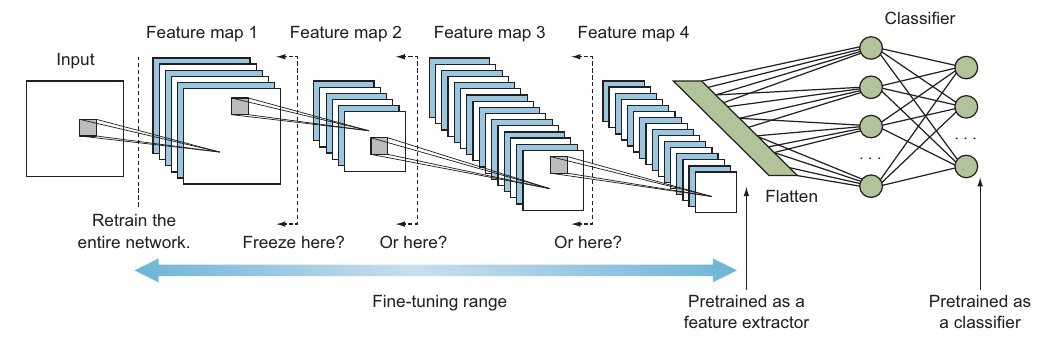

## Estratégias de Transfer Learning

A figura acima ilustra como o conhecimento de uma CNN pré-treinada pode ser aproveitado em uma nova tarefa, mostrando diferentes pontos em que podemos congelar as camadas ou continuar o treinamento da rede.

- Pretrained as a classifier: utiliza-se a rede completa, incluindo o classificador original, sem modificar seus pesos. É adequado quando as classes do problema correspondem às classes originais.
- Pretrained as a feature extractor: congelam-se as camadas convolucionais e substitui-se o classificador original por um novo, treinado para as classes da nova tarefa.
- Fine-tuning: descongelam-se algumas camadas convolucionais, mantendo outras congeladas, e treinam-se conjuntamente as camadas selecionadas e o novo classificador.

### Como interpretar os pontos de congelamento?

Da esquerda para a direita, os feature maps representam características progressivamente mais complexas, extraídas pelas camadas da rede:

- Camadas iniciais: aprendem características genéricas, como bordas, cores e texturas. Geralmente, são mantidas congeladas.
- Camadas intermediárias: identificam formas e combinações de características. Podem ser ajustadas conforme a similaridade entre os domínios.
- Camadas finais: aprendem características mais específicas da tarefa original. Podem ser descongeladas para adaptação ao novo problema.

A faixa azul indica as possíveis regiões de fine-tuning. Quanto mais camadas forem descongeladas, maior será a capacidade de adaptação da rede, mas também maior poderá ser o custo computacional e o risco de overfitting.

Conclusão: o ponto de congelamento depende da similaridade entre o domínio original e o novo domínio, bem como da quantidade de dados disponíveis. Em geral, é recomendável começar congelando a maior parte da rede e descongelar gradualmente algumas camadas finais, se necessário.

##Choosing the appropriate level of transfer learning
1. **The target dataset is small and similar to the source dataset**: Freeze the feature extraction part of the network and only retrain the
classifier.
1. **The target dataset is large and similar to the source dataset**: Freeze the feature extraction part and retrain the classifier. So a good start is to freeze approximately
60–80% of the pretrained network and retrain the rest on the new data.
1. **Target dataset is small and different from the source dataset**: However, since you have a
small dataset, fine-tuning the entire network on the dataset might not be a good idea,
because doing so will make it prone to overfitting. A midway solution will work better
in this case. A good start is to freeze approximately the first third or half of the pre-
trained network. After all, the early layers contain very generic feature maps that will
be useful for your dataset even if it is very different.
1. **Target dataset is large and different from the source dataset**: Since the new dataset is large, you might be tempted to just train the entire network
from scratch and not use transfer learning at all. However, in practice, it is often still
very beneficial to initialize weights from a pretrained model. Since the new dataset is large, you might be tempted to just train the entire network
from scratch and not use transfer learning at all. However, in practice, it is often still
very beneficial to initialize weights from a pretrained model

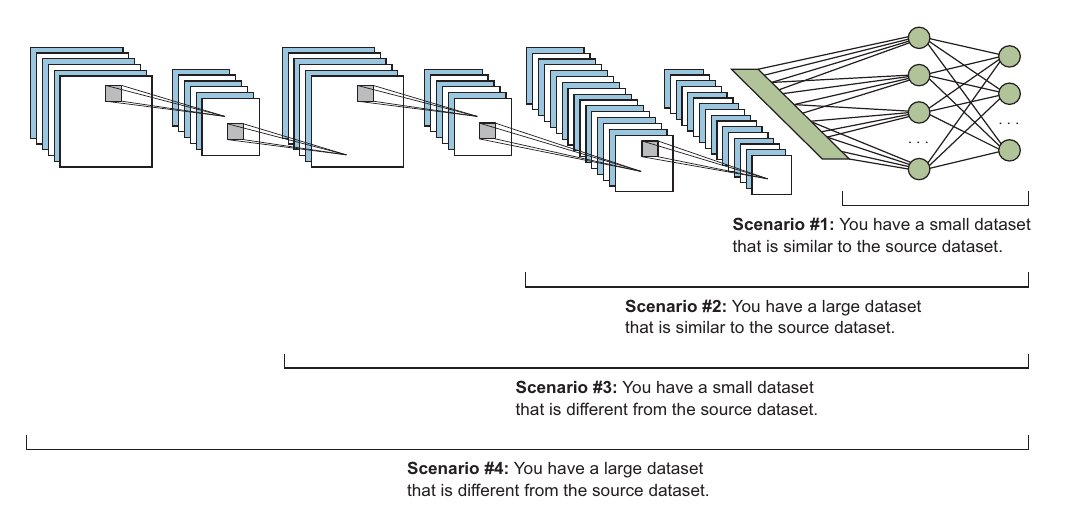

##A pretrained network as a feature extractor
In this project, we use a very small amount of data to train a classifier that detects
images of dogs and cats. This is a pretty simple project, but the goal of the exercise is
to see how to implement transfer learning when you have a very small amount of data
and the target domain is similar to the source domain (scenario 1). As explained in
this chapter, in this case, we will use the pretrained convolutional network as a feature
extractor. This means we are going to freeze the feature extractor part of the network,
add our own classifier, and then retrain the network on our new small dataset.

The process to use a pretrained model as a feature extractor is well established:
1. Import the necessary libraries.
2. Preprocess the data to make it ready for the neural network.
3. Load pretrained weights from the VGG16 network trained on a large dataset.
4. Freeze all the weights in the convolutional layers (feature extraction part).
Remember, the layers to freeze are adjusted depending on the similarity of the
new task to the original dataset. In our case, we observed that ImageNet has a
lot of dog and cat images, so the network has already been trained to extract
the detailed features of our target object.
5. Replace the fully connected layers of the network with a custom classifier. You
can add as many fully connected layers as you see fit, and each can have as
many hidden units as you want. For simple problems like this, we will just add
one hidden layer with 64 units. You can observe the results and tune up if the
model is underfitting or down if the model is overfitting. For the softmax layer,
the number of units must be set equal to the number of classes (two units, in
our case).
6. Compile the network, and run the training process on the new data of cats and
dogs to optimize the model for the smaller dataset.
7. Evaluate the model.

# Uma rede pré-treinada como extratora de características (Feature Extractor)

Neste projeto, utilizamos uma quantidade muito pequena de dados para treinar um classificador capaz de identificar imagens de cães e gatos. Embora seja um projeto relativamente simples, o objetivo do exercício é demonstrar como implementar Transfer Learning quando temos poucos dados e o domínio-alvo é semelhante ao domínio de origem (Cenário 1).

Como explicado neste capítulo, nessa situação, utilizaremos a rede convolucional pré-treinada como uma extratora de características (feature extractor). Isso significa que vamos congelar a parte da rede responsável pela extração de características, adicionar nosso próprio classificador e, em seguida, treinar esse classificador com nosso novo conjunto de dados, de tamanho reduzido.

O procedimento para utilizar um modelo pré-treinado como extrator de características é bem estabelecido:

1. Importar as bibliotecas necessárias.

2. Pré-processar os dados, preparando as imagens para serem utilizadas pela rede neural.

3. Carregar os pesos pré-treinados da rede VGG16, treinada em uma grande base de dados.

4. Congelar todos os pesos das camadas convolucionais, responsáveis pela extração de características.

- Lembre-se de que a escolha das camadas a serem congeladas depende da similaridade entre a nova tarefa e o conjunto de dados original. Neste exemplo, observamos que o ImageNet contém muitas imagens de cães e gatos. Portanto, a rede já foi treinada para extrair características detalhadas desses objetos, o que favorece sua utilização na nova tarefa.

5. Substituir as camadas totalmente conectadas por um classificador personalizado.

- Podemos adicionar quantas camadas totalmente conectadas (fully connected layers) forem necessárias, cada uma com a quantidade desejada de neurônios ocultos. Para problemas simples como este, adicionaremos apenas uma camada oculta com 64 neurônios.

- Os resultados podem ser utilizados para ajustar a complexidade do modelo: aumentar a capacidade caso ocorra underfitting (subajuste) ou reduzi-la caso ocorra overfitting (sobreajuste).

- Na camada de saída softmax, o número de neurônios deve corresponder ao número de classes. Neste caso, utilizaremos dois neurônios: um para cães e outro para gatos.

6. Compilar a rede e realizar o treinamento.

- Treinaremos o modelo com as novas imagens de cães e gatos, otimizando o classificador para o conjunto de dados reduzido.

7. Avaliar o modelo.

- Por fim, avaliaremos o desempenho do classificador em dados independentes, verificando sua capacidade de identificar corretamente imagens de cães e gatos.

Observação técnica: no cenário de feature extraction, os pesos da VGG16 permanecem congelados durante o treinamento. Portanto, tecnicamente, não treinamos novamente a rede convolucional inteira, treinamos apenas as novas camadas do classificador. Se posteriormente descongelarmos algumas camadas convolucionais para adaptá-las ao novo conjunto de dados, passaremos a utilizar a estratégia de fine-tuning.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.preprocessing import image
from keras.applications import imagenet_utils
from keras.applications import vgg16
from tensorflow.keras.optimizers import Adam, SGD
from keras.metrics import categorical_crossentropy
from sklearn.metrics import confusion_matrix
import itertools
import matplotlib.pyplot as plt
from keras.layers import Dense, Flatten, Dropout, BatchNormalization
from keras.models import Model
from sklearn.datasets import load_files
from keras.utils import to_categorical
import numpy as np
from tensorflow.keras.utils import load_img
from tensorflow.keras.utils import img_to_array
from keras.applications.vgg16 import preprocess_input
from tqdm import tqdm
import time
from keras import backend as K

In [4]:
# função para calcular o tempo de treinamento da rede
def processing_time(start_t, finish_t):
  a = finish_t - start_t
  if a < 0:
    print('Error! time negative!')
    return
  hora = 0
  min = a // 60
  seg = a % 60
  if min > 59:
    hora = min // 60
    min = min % 60
  if hora > 0:
    print("\nElapsed time:%ih%im%is"% (hora, min, seg))
  else:
    print("\nElapsed time:%im%is"% (min, seg))

# função para plotar os gráficos da acurária e perda
def plot_acc_loss(h):
  plt.figure(figsize = (11,5))
  plt.subplot(1,2,1)
  plt.plot(h.history['loss'], label = 'Treino')
  plt.plot(h.history['val_loss'], label = 'Validação')
  plt.xlabel('Épocas')
  plt.ylabel('Função Custo')
  plt.title('loss')
  plt.xticks()
  plt.yticks()
  plt.legend()
  plt.grid()
  plt.subplot(1,2,2)
  plt.plot(h.history['accuracy'], label = 'Treino')
  plt.plot(h.history['val_accuracy'], label = 'Validação')
  plt.xlabel('Épocas')
  plt.ylabel('Acurácia')
  plt.title('accuracy')
  plt.xticks()
  plt.yticks()
  plt.legend()
  plt.tight_layout()
  plt.grid()
  plt.show()

##Preprocess the data

Preprocess the data to make it ready for the neural network. Keras has an
ImageDataGenerator class that allows us to easily perform image augmentation
on the fly; you can read about it at https://keras.io/api/preprocessing/image.

In this example, we use ImageDataGenerator to generate our image tensors,
but for simplicity, we will not implement image augmentation.
The ImageDataGenerator class has a method called `flow_from_directory()`
that is used to read images from folders containing images.

ImageDataGenerator generates batches of
tensor image data with real-time data
augmentation. The data will be looped over
(in batches). In this example, we won’t be
doing any image augmentation.

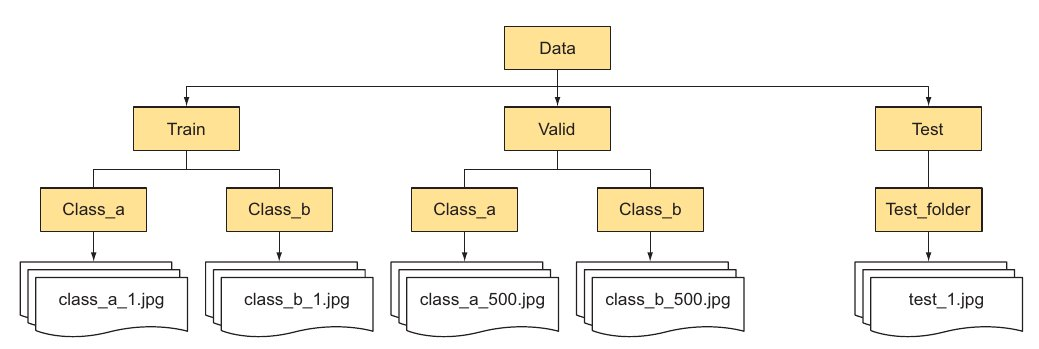

In [5]:
# Dataset drive path
train_path  = '/content/drive/MyDrive/Colab Notebooks/Datasets/data/train'
valid_path  = '/content/drive/MyDrive/Colab Notebooks/Datasets/data/valid'
test_path  = '/content/drive/MyDrive/Colab Notebooks/Datasets/data/test'

# Reading dataset
train_batches = ImageDataGenerator(preprocessing_function=vgg16.preprocess_input).flow_from_directory(
    train_path, target_size=(224,224), batch_size=30)
test_batches = ImageDataGenerator(preprocessing_function=vgg16.preprocess_input).flow_from_directory(
    test_path, target_size=(224,224), batch_size=30)
valid_batches = ImageDataGenerator(preprocessing_function=vgg16.preprocess_input).flow_from_directory(
    valid_path, target_size=(224,224), batch_size=30)

# print dataset samples distribution
print('Train samples:', train_batches.samples)
print('Test samples:', test_batches.samples)
print('Validation samples:', valid_batches.samples)

Found 202 images belonging to 2 classes.
Found 451 images belonging to 2 classes.
Found 103 images belonging to 2 classes.
Train samples: 202
Test samples: 451
Validation samples: 103


In [6]:
train_batches.num_classes

2

In [7]:
train_batches.class_indices

{'cat': 0, 'dog': 1}

##Load in pretrained weights
Load in pretrained weights from the VGG16 network trained on a large dataset.
Similar to the examples in this chapter, we download the VGG16 network from
Keras and download its weights after they are pretrained on the I**mageNet dataset**. Remember that we want to remove the classifier part from this network, so
we set the parameter `include_top=False`.

In [14]:
K.clear_session()
base_model = vgg16.VGG16(weights = "imagenet", include_top=False, input_shape = (224,224, 3))
base_model.summary(show_trainable=True)

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv1 (Conv2D)       │ (None, 224, 224, 64)  │      1,792 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv2 (Conv2D)       │ (None, 224, 224, 64)  │     36,928 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_pool (MaxPooling2D)  │ (None, 112, 112, 64)  │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv1 (Conv2D)       │ (None, 112, 112, 128) │     73,856 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv2 (Conv2D)       │ (None, 112, 112, 128) │    147,584 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_pool (MaxPooling2D)  │ (None, 56, 56, 128)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv1 (Conv2D)       │ (None, 56, 56, 256)   │    295,168 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv2 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv3 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_pool (MaxPooling2D)  │ (None, 28, 28, 256)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv1 (Conv2D)       │ (None, 28, 28, 512)   │  1,180,160 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv2 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv3 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_pool (MaxPooling2D)  │ (None, 14, 14, 512)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv1 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv2 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv3 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_pool (MaxPooling2D)  │ (None, 7, 7, 512)     │          0 │   -   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

##Freeze all the weights in the convolutional layers
Freeze all the weights in the convolutional layers (feature extraction part). We
freeze the convolutional layers from the base_model created in the previous step and use that as a feature extractor, and then add a classifier on top of it in
the next step.

In [15]:
# iterate through its layers and lock them to make them not trainable with this code
for layer in base_model.layers:
    layer.trainable = False

base_model.summary(show_trainable=True)

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv1 (Conv2D)       │ (None, 224, 224, 64)  │      1,792 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv2 (Conv2D)       │ (None, 224, 224, 64)  │     36,928 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_pool (MaxPooling2D)  │ (None, 112, 112, 64)  │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv1 (Conv2D)       │ (None, 112, 112, 128) │     73,856 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv2 (Conv2D)       │ (None, 112, 112, 128) │    147,584 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_pool (MaxPooling2D)  │ (None, 56, 56, 128)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv1 (Conv2D)       │ (None, 56, 56, 256)   │    295,168 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv2 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv3 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_pool (MaxPooling2D)  │ (None, 28, 28, 256)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv1 (Conv2D)       │ (None, 28, 28, 512)   │  1,180,160 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv2 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv3 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_pool (MaxPooling2D)  │ (None, 14, 14, 512)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv1 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv2 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv3 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_pool (MaxPooling2D)  │ (None, 7, 7, 512)     │          0 │   -   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

##Add the new classifier
Add the new classifier, and build the new model. We add a few layers on top of
the base model. In this example, we add one fully connected layer with 64 hidden units and a softmax with 2 hidden units. We also add batch norm and dropout layers to avoid overfitting.

Uses the `get_layer` method to save the last
layer of the network. Then saves the output of
the last layer to be the input of the next layer.

Adds one fully
connected layer
that has 64 units
and batchnorm,
dropout, and
softmax layers.

In [16]:
# use “get_layer” method to save the last layer of the network
# save the output of the last layer to be the input of the next layer
last_layer = base_model.get_layer('block5_pool')
last_output = last_layer.output

# flatten the classifier input which is output of the last layer of VGG16 model
x = Flatten()(last_output)

# add FC layer, which has 64 units and relu activation
x = Dense(64, activation='relu', name='FC_2')(x)
# x = BatchNormalization()(x)
x = Dropout(0.5)(x)
# add our new softmax layer with 2 hidden units
x = Dense(2, activation='softmax', name='softmax')(x)

# instantiate a new_model using keras’s Model class
new_model = Model(inputs=base_model.input, outputs=x)
# salva os pesos e bias com os valores inicias
initial_weights = new_model.get_weights()
# print the new_model summary
new_model.summary(show_trainable=True)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv1 (Conv2D)       │ (None, 224, 224, 64)  │      1,792 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv2 (Conv2D)       │ (None, 224, 224, 64)  │     36,928 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_pool (MaxPooling2D)  │ (None, 112, 112, 64)  │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv1 (Conv2D)       │ (None, 112, 112, 128) │     73,856 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv2 (Conv2D)       │ (None, 112, 112, 128) │    147,584 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_pool (MaxPooling2D)  │ (None, 56, 56, 128)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv1 (Conv2D)       │ (None, 56, 56, 256)   │    295,168 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv2 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv3 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_pool (MaxPooling2D)  │ (None, 28, 28, 256)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv1 (Conv2D)       │ (None, 28, 28, 512)   │  1,180,160 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv2 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv3 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_pool (MaxPooling2D)  │ (None, 14, 14, 512)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv1 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv2 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv3 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_pool (MaxPooling2D)  │ (None, 7, 7, 512)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ flatten (Flatten)           │ (None, 25088)         │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ FC_2 (Dense)                │ (None, 64)            │  1,605,696 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 64)            │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ softmax (Dense)             │ (None, 2)             │        130 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 16,320,514 (62.26 MB)

 Trainable params: 1,605,826 (6.13 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Compile the model and run the training process

In [17]:
# compile model
new_model.compile(Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [18]:
# início do treinamento da rede
start_time = time.time()
# carrega os pesos e bias com os valores inicias, para um novo treinamento da rede
new_model.set_weights(initial_weights)
# fit model
hist = new_model.fit(train_batches, validation_data=valid_batches, epochs=10, verbose=1)

# steps_per_epoch_ = train_batches.samples//train_batches.batch_size
# validation_steps_ = valid_batches.samples//valid_batches.batch_size
# hist = new_model.fit(train_batches, steps_per_epoch=steps_per_epoch_,
#                    validation_data=valid_batches, validation_steps=validation_steps_, epochs=20, verbose=1)

# tempo total de treinamento da rede
processing_time(start_time, time.time())

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 786ms/step - accuracy: 0.5248 - loss: 13.5978 - val_accuracy: 0.7282 - val_loss: 2.7244
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 273ms/step - accuracy: 0.8564 - loss: 2.7315 - val_accuracy: 0.9126 - val_loss: 0.7717
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 306ms/step - accuracy: 0.9505 - loss: 0.3167 - val_accuracy: 0.9417 - val_loss: 0.4849
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 293ms/step - accuracy: 0.9653 - loss: 0.3404 - val_accuracy: 0.9417 - val_loss: 0.2987
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 269ms/step - accuracy: 0.9653 - loss: 0.2609 - val_accuracy: 0.9515 - val_loss: 0.2885
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 268ms/step - accuracy: 0.9901 - loss: 0.0801 - val_accuracy: 0.9515 - val_loss: 0.2258
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 273ms/step - accuracy: 0.9901 - loss: 0.0437 - val_accuracy: 0.9612 - val_loss: 0.1723
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 274ms/step - accuracy: 1.0000 - loss: 0.0064 - val_accuracy: 0.9709 - val_los

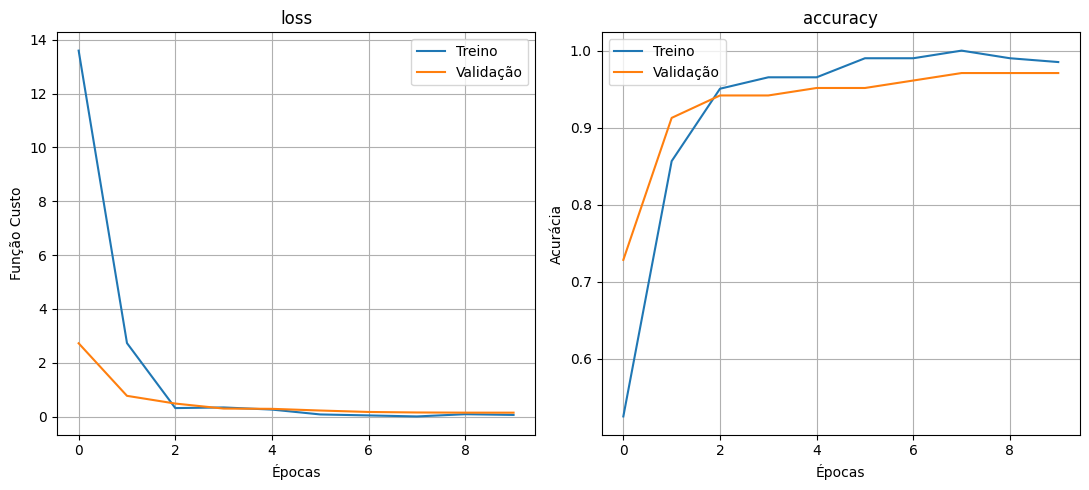

In [19]:
plot_acc_loss(hist)

##Evaluate the model
First, let’s define the `load_dataset()` method that we will
use to convert our dataset into tensors.

In [20]:
def load_dataset(path):
    data = load_files(path)
    paths = np.array(data['filenames'])
    targets = to_categorical(np.array(data['target']))
    return paths, targets

test_files, test_targets = load_dataset(test_path)

In [25]:
test_files.shape

(451,)

In [23]:
test_targets.shape

(451, 2)

Then, we create test_tensors to evaluate the model on them.

In [26]:
def path_to_tensor(img_path):
    # loads RGB image as PIL.Image.Image type
    img = load_img(img_path, target_size=(224, 224))
    # convert PIL.Image.Image type to 3D tensor with shape (224, 224, 3)
    x = img_to_array(img)
    # convert 3D tensor to 4D tensor with shape (1, 224, 224, 3) and return 4D tensor
    return np.expand_dims(x, axis=0)

def paths_to_tensor(img_paths):
    list_of_tensors = [path_to_tensor(img_path) for img_path in tqdm(img_paths)]
    return np.vstack(list_of_tensors)

test_tensors = preprocess_input(paths_to_tensor(test_files))

100%|██████████| 451/451 [00:01<00:00, 344.20it/s]


In [27]:
test_tensors.shape

(451, 224, 224, 3)

Now we can run Keras’s `evaluate()` method to calculate the model accuracy.

In [28]:
# evaluate and print test accuracy and loss
score = new_model.evaluate(test_tensors, test_targets)
print('\nTest accuracy: %.1f%%' % (score[1]*100))
print('Test loss: %.3f' % (score[0]))

15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 269ms/step - accuracy: 0.9645 - loss: 0.3622

Test accuracy: 96.5%
Test loss: 0.362


The model has achieved an accuracy about 96% in less than 3 minutes of training (GPU).
This is very good, given our very small dataset.

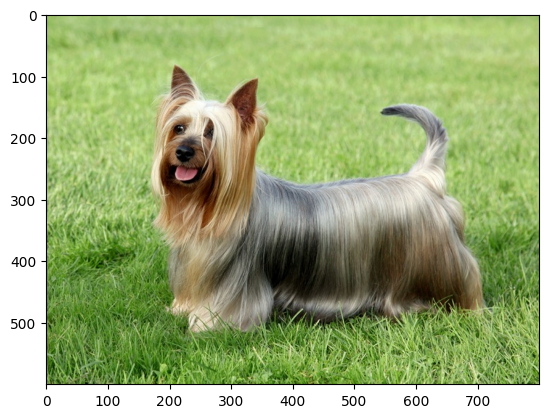

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
cachorro 100.00%


In [32]:
# cachorros
img_name = 'Australian_terrier.jpeg'
# img_name = 'Yorkshire Terrier.jpg'
#img_name = 'fila.jpg'
#img_name = 'bullmastiff2.jpg'
#img_name = 'dog5.jpg'
# img_name = 'dog4.jpg'
# img_name = 'dog.jpg'

# gatos
#img_name = 'cat1.jpg'
#img_name = 'cat2.jpg'
#img_name = 'cat3.jpg'
#img_name = 'cat4.jpg'
# img_name = 'cat5.jpg'

# outros bichos
# img_name = 'warthog-2.jpg'
#img_name = 'vaca1.jpg'
#img_name = 'aranha.jpg'
# img_name = 'sapo.jpeg'
#img_name = 'horse.jpeg'

path = '/content/drive/MyDrive/Colab Notebooks/images/' + img_name
image = load_img(path, target_size=(224, 224))
image2 = load_img(path)
plt.imshow(image2)
plt.show()

# convert the image pixels to a numpy array
image = img_to_array(image)
# reshape data for the model
image = image.reshape((1, image.shape[0], image.shape[1], image.shape[2]))
# prepare the image for the VGG model
image = preprocess_input(image)
# predict the probability across all output classes
yhat = new_model.predict(image)

# print prediction
a=yhat.reshape(-1)
if a[0] > a[1]:
  print('gato %.2f%%' % (a[0]*100))
else:
  print('cachorro %.2f%%' % (a[1]*100))


Exercícios:
1. Se no treinamento da rede o sistema responder com alguma `UserWarning`, procure resolver o problema de compatibilidade encontrando alguma solução nos sites de ajuda (stackoverflow.com, support.google.com, etc.)
1. Melhore a performance da rede efetuando a sintonia dos hiperparâmetros da camada de classificação (full connected layers).
1. Introduza mais uma camada full connected com um valor de neurônios que você julgar adequado. Faça o treinamento e verifique se a performance melhorou.
1. Se o treinamento do modelo demonstrou `overfitting`, utilize métodos de regularização (dropout, batchnormalization, l2, etc.) nas camadas FC e verifique o desempenho.
1. Utilize outros otimizadores (SGD, RMSprop, Adagrad) e verifique qual obteve o melhor desempenho.
1. Redistribua entre as pastas o banco de dados utilizado (cats & dogs) de forma a ter a seguinte distribuição: 60% treinamento, 30% validação e 10% para teste. Refaça o treinamento e verifique como ficou a performance da rede.
1. Utilizando a topologia de rede que obteve melhor resultado, motar um banco de dados próprio, com 2 classes correlatas, que você irá escolher das 1000 classes ImageNet. Cada classe deverá conter 60 imagens, sendo esta: 40 treinamento, 10 para validação e 10 para teste.
1. Como a rede se comportou? Utilizar métricas para analisar os resultados obtidos.

## Referências
[1] [Elgendy, M. **Deep Learning for Vision Systems**. Manning Publications Co. Shelter Island, NY. 2020.](https://github.com/moelgendy/deep_learning_for_vision_systems/tree/master/chapter_06)

[2] https://towardsdatascience.com/transfer-learning-for-image-classification-using-tensorflow-71c359b56673

[3] https://medium.com/mlearning-ai/image-classification-with-transfer-learning-on-tensorflow-68b6bc87ef4b

[4] https://www.kaggle.com/code/kmkarakaya/transfer-learning-for-image-classification

[5] https://www.geeksforgeeks.org/multiclass-image-classification-using-transfer-learning/

[6] https://dev.mrdbourke.com/tensorflow-deep-learning/04_transfer_learning_in_tensorflow_part_1_feature_extraction/